# Lab #2: Probability, Distributions, and Statistical Questions

    Saraliba Auch
    10/14/2026

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy import signal
from scipy import stats

### **Problem 1**

**In lecture and homework we explored how the convolution can be used to calculate the probability of a sum or average. For this problem, we are going to imagine that we are looking for gamma-ray sources (e.g. with the Fermi telescope). In this kind of telescope, there is a background noise of cosmic-rays (electrons and protons, mostly) that probides a discrete noise term across the sky that precisely follows a Possion distribution. To detect a gamma-ray source, you need to ask what is the probability that the cosmic-ray bachground would have given you a measurement as signal-like or more that the signal you received.**

**To set up the problem, assume in 1 day the average cosmic-ray background is some number X (pick something between 0.5 and 10, with different values for you and your lab partner); and the average number of gamma-rays emitted by your hypothetical source is Y (pick something larger than X).**

**A) Show how the probability disribution of the background changes as you integrate (sum) for more days.**

In [2]:
#Average cosmix-ray background:
x = 5
#Average number of gamma-rays emitted
y = 9

Text(0, 0.5, 'Probability')

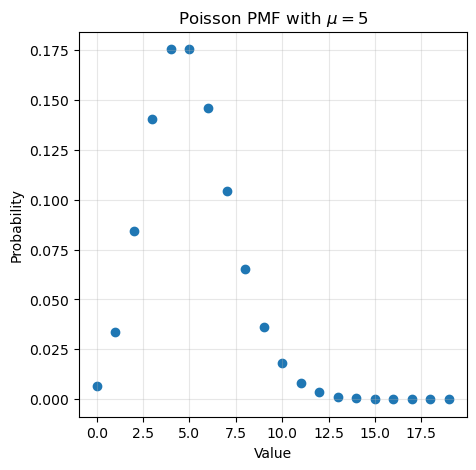

In [3]:
#Creates an evenly spaced array, need to be integers or else the value is zero
#need k to be distributed enough to capture enough of the distributions for convoluting a lot of times
k = np.arange(0,20,1)

#The pmf of the the poisson distribution defined above
x_pmf = stats.poisson.pmf(k, mu=x)

#plot of the distribution
fig, axes = plt.subplots(figsize=(5, 5))
axes.scatter(k, 
             x_pmf)
axes.grid(alpha=0.3)
axes.set_title(r"Poisson PMF with $\mu=5$")
axes.set_xlabel("Value")
axes.set_ylabel("Probability")

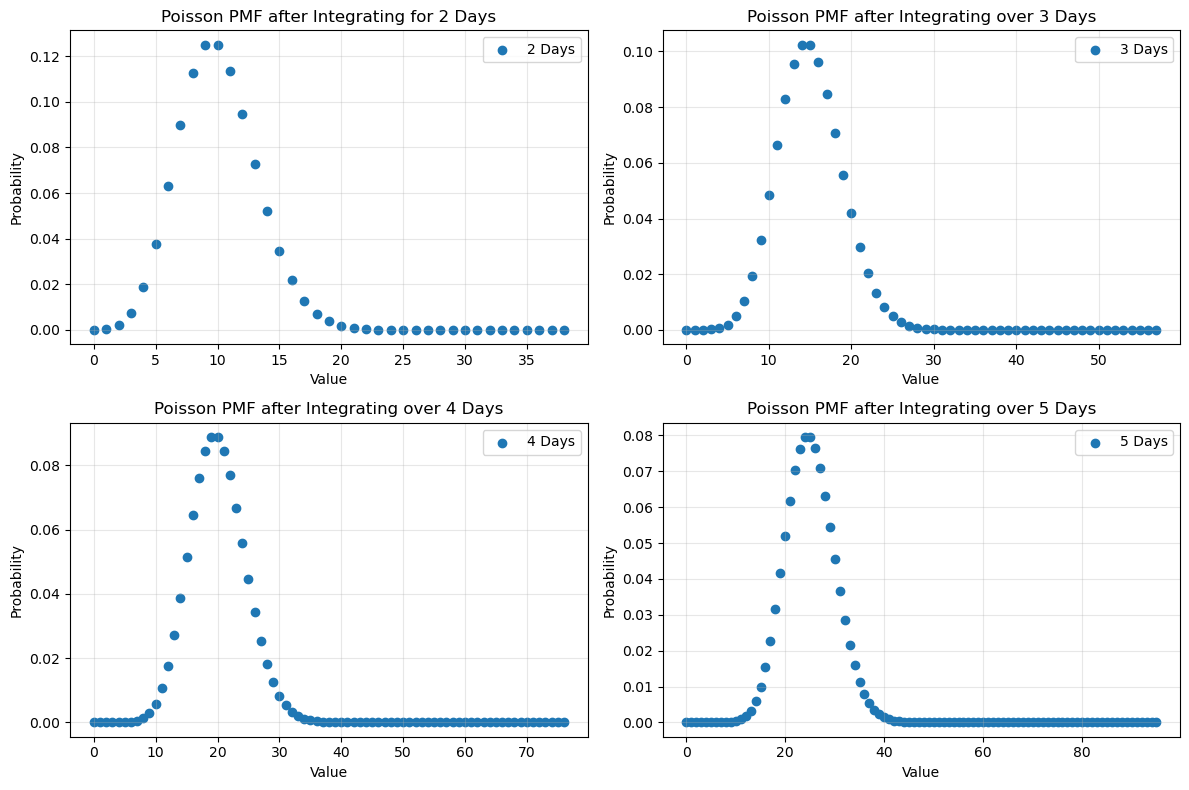

In [4]:
fig, axes = plt.subplot_mosaic(
    '''
    AB
    CD
    ''',
    figsize=(12, 8))

#First Convolution: Probability of two days of data summed together
con_1 = np.convolve(x_pmf,x_pmf)
#Calculates the new x-values, k starts at zero so k[0] doesn't need to be considered
x_sum = np.arange(len(con_1))
axes['A'].scatter(x_sum, 
             con_1,
               label = "2 Days")
axes['A'].grid(alpha=0.3)
axes['A'].set_title(r"Poisson PMF after Integrating for 2 Days")
axes['A'].set_xlabel("Value")
axes['A'].set_ylabel("Probability")
axes['A'].legend()

#Second Convolution: Probability of three days of data summed together
con_2 = np.convolve(con_1,x_pmf) 
#Calculates the new x-values
x_sum = 2*k[0] + np.arange(len(con_2)) 
axes['B'].scatter(x_sum, 
             con_2,
               label = "3 Days")
axes['B'].grid(alpha=0.3)
axes['B'].set_title(r"Poisson PMF after Integrating over 3 Days")
axes['B'].set_xlabel("Value")
axes['B'].set_ylabel("Probability")
axes['B'].legend()

#Third Convolution: Probability of four days of data summed together
con_3 = np.convolve(con_2,x_pmf) 
#Calculates the new x-values
x_sum = k[0] + k[0] + np.arange(len(con_3)) 
axes['C'].scatter(x_sum, 
             con_3,
               label = "4 Days")
axes['C'].grid(alpha=0.3)
axes['C'].set_title(r"Poisson PMF after Integrating over 4 Days")
axes['C'].set_xlabel("Value")
axes['C'].set_ylabel("Probability")
axes['C'].legend()

#Second Convolution: Probability of five days of data summed together
con_4 = np.convolve(con_3,x_pmf) 
#Calculates the new x-values
x_sum = k[0] + k[0] + np.arange(len(con_4)) 
axes['D'].scatter(x_sum, 
             con_4,
               label = "5 Days")
axes['D'].grid(alpha=0.3)
axes['D'].set_title(r"Poisson PMF after Integrating over 5 Days")
axes['D'].set_xlabel("Value")
axes['D'].set_ylabel("Probability")
axes['D'].legend()

plt.tight_layout()
plt.show()

    The distribution become more spread out and shifts across the x-axis to the right.

**B) Show that after 5 days, the summed probability distribution is still a Possion distribution. Explain why this makes sense from a mathmatical and conceptual point of view.**

    5 days would mean four convolutions

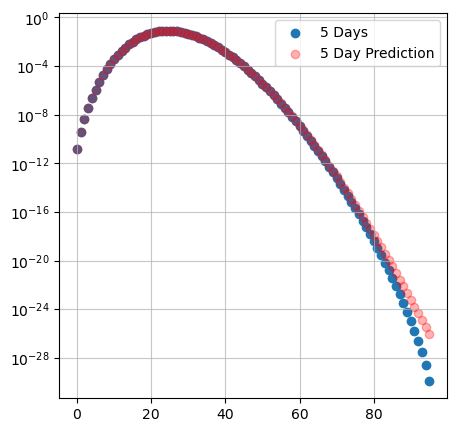

In [5]:
fig, axes = plt.subplots(figsize=(5,5))

#PMF for 5 days
axes.scatter(x_sum, 
             con_4,
            label = '5 Days')
#Prediced PMF for a Possion distribution with the same mu as the above data
axes.scatter(x_sum,
             stats.poisson.pmf(x_sum, mu=sum(con_4*x_sum)),
             color = 'red',
             alpha = 0.3,
             label = '5 Day Prediction')
axes.set_yscale('log')
axes.grid(alpha=.7)
axes.legend()

    As the graph shows, the convolution is very similiar to the predicted Poisson distribution with the same mu value. You will only get into trouble when measureing values in the right tail. This makes sense since I didn't add together that many days, so the convolution would not shift that much from the original distribution.

**C) Show how the probabiliy distribution evolves as you average days. Calculate for many different ranges of days, and explore the shape of the distribution as the number of days becomes larger. Discuss this in relation to both B) and the central limit theorem**

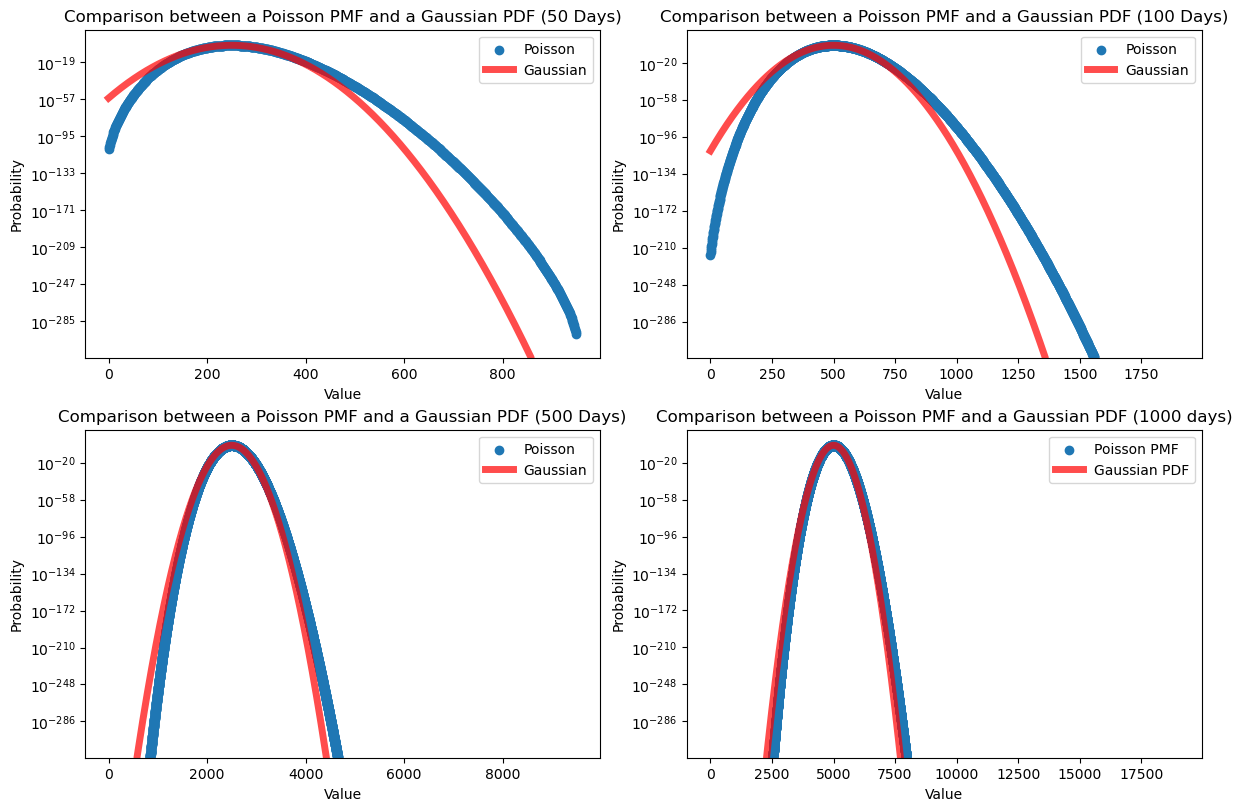

In [6]:
#Graph the Convolotion for 5,50,100, and 1000 days. Each Graph follows the same code, but just different value
#Probably should just make a function next time...sorry
fig, axes = plt.subplot_mosaic(
    '''
    AB
    CD
    ''',
    figsize=(12, 8),
    constrained_layout = True
)

axes['A'].set_yscale('log')
axes['B'].set_yscale('log')
axes['C'].set_yscale('log')
axes['D'].set_yscale('log')

#resets the probability for 2 days
prob = np.convolve(x_pmf,x_pmf) 
#number of days I want to convolve
num_days = 50
#makes an array for the additional number of days I need to convolve for
array = np.arange(0,num_days-2)
#the convolution
for day in array:
    prob = np.convolve(prob, x_pmf) 
    x_sum = np.arange(len(prob)) 

axes['A'].scatter(x_sum,prob,label = "Poisson")
axes['A'].plot(x_sum,
               stats.norm.pdf(x_sum,
                              loc= np.sum(prob*x_sum), #The mean for the series of convolutions I just performed
                              scale = np.sqrt(np.sum(prob * (x_sum - np.sum(prob*x_sum))**2))), #The sigma for the convolutions I just performed
            label = "Gaussian",
            linewidth=5,
            alpha = 0.7,
            color = 'red')
axes['A'].set_title(r"Comparison between a Poisson PMF and a Gaussian PDF (50 Days)")
axes['A'].set_xlabel("Value")
axes['A'].set_ylabel("Probability")
axes['A'].legend()
#rinse and repeat
prob = np.convolve(x_pmf,x_pmf) 
num_days = 100
array = np.arange(0,num_days-2)
for day in array:
    prob = np.convolve(prob, x_pmf) 
    x_sum = np.arange(len(prob)) 

axes['B'].scatter(x_sum, 
            prob,
            label = "Poisson",)
axes['B'].plot(x_sum, 
               stats.norm.pdf(x_sum, 
                            loc= np.sum(prob*x_sum), 
                           scale = np.sqrt(np.sum(prob * (x_sum - np.sum(prob*x_sum))**2))),
            label = "Gaussian",
            linewidth=5,
            alpha = 0.7,
            color = 'red')
axes['B'].set_title(r"Comparison between a Poisson PMF and a Gaussian PDF (100 Days)")
axes['B'].set_xlabel("Value")
axes['B'].set_ylabel("Probability")
axes['B'].legend()

prob = np.convolve(x_pmf,x_pmf) 
num_days = 500
array = np.arange(0,num_days-2)
for day in array:
    prob = np.convolve(prob, x_pmf) 
    x_sum = np.arange(len(prob))

axes['C'].scatter(x_sum, 
            prob,
            label = "Poisson",)
axes['C'].plot(x_sum, 
            stats.norm.pdf(x_sum, 
                           loc= np.sum(prob*x_sum), 
                           scale = np.sqrt(np.sum(prob * (x_sum - np.sum(prob*x_sum))**2))),
            label = "Gaussian",
            linewidth=5,
            alpha = 0.7,
            color = 'red')
axes['C'].set_title(r"Comparison between a Poisson PMF and a Gaussian PDF (500 Days)")
axes['C'].set_xlabel("Value")
axes['C'].set_ylabel("Probability")
axes['C'].legend()

prob = np.convolve(x_pmf,x_pmf)
num_days = 1000
array = np.arange(0,num_days-2)
for day in array:
    prob = np.convolve(prob, x_pmf)
    x_sum = np.arange(len(prob)) 

axes['D'].scatter(x_sum, 
            prob,
            label = "Poisson PMF",)
axes['D'].plot(x_sum, 
            stats.norm.pdf(x_sum, 
                           loc= np.sum(prob*x_sum), 
                           scale = np.sqrt(np.sum(prob * (x_sum - np.sum(prob*x_sum))**2))),
            label = "Gaussian PDF",
            linewidth=5,
            alpha = 0.7,
            color = 'red')
axes['D'].set_title(r"Comparison between a Poisson PMF and a Gaussian PDF (1000 days)")
axes['D'].set_xlabel("Value")
axes['D'].set_ylabel("Probability")
axes['D'].legend()

plt.show()

    As expexted, the distribution approaches a Gaussian as it is convoluted more. 
    The distribution is relitvely Poisson-like the less I convolve it. It only starts looking more Gaussian after doing a lot of convolutions. Which agrees with the central limit theorem

**D) Pick some number of days N, and assume you saw Y*N gamma rays from your source. Calculate the 'sigma' of your observation. [In reality the number of gamma-rays seen from a source will also fluctuate, but we're going to ignore that complication for a couple of labs.\]**

In [7]:
#number of days
N = 50
#numer of gammas rays from my source
gam_ray = y * N

In [8]:
#resets probability so it is the convolution of two days
prob = np.convolve(x_pmf,x_pmf)
#Same loop used above to convolve the data for a certain number of days
array = np.arange(0,N-2)
for day in array:
    prob = np.convolve(prob, x_pmf)
    x_sum = np.arange(len(prob))

In [9]:
#gets the probability of measureing that number of gamma rays. Distribution is still Poisson enough
pos_sf = stats.poisson.sf(gam_ray, mu=N*x)
#Calculates the isf of a Gaussian, using the probability calculated above
pos_isf = stats.norm.isf(pos_sf)
print(pos_isf)

11.393516862469921


    The sigma for measureing 450 gamma rays over 50 days is 11.4 sigma!!! A very significant discovery.

## Problem 2

**Pick a skewed continuous distribution, such as a Rayleigh, that describes your background over some observing interval.**

**A) Show how the distribution changes as you average over more observing intervals.**

    I choose a Rayleigh

Text(0, 0.5, 'Probability')

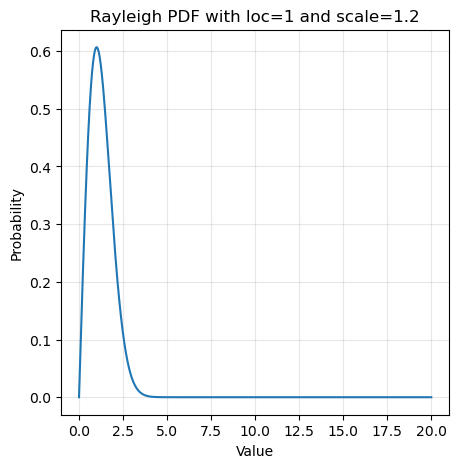

In [10]:
#need an evenly distributed array to convolve properly
x = np.linspace(0,20,1000)
#Rayleigh is continuous, so I will need to integrate the convolution
dx = x[1]-x[0]
#My pdf for my normal rayleigh
ray_pdf = stats.rayleigh.pdf(x)

fig, axes = plt.subplots(figsize=(5, 5))
axes.plot(x, ray_pdf)
axes.grid(alpha=0.3)
axes.set_title(r"Rayleigh PDF with loc=1 and scale=1.2")
axes.set_xlabel("Value")
axes.set_ylabel("Probability")
#axes.set_yscale('log')

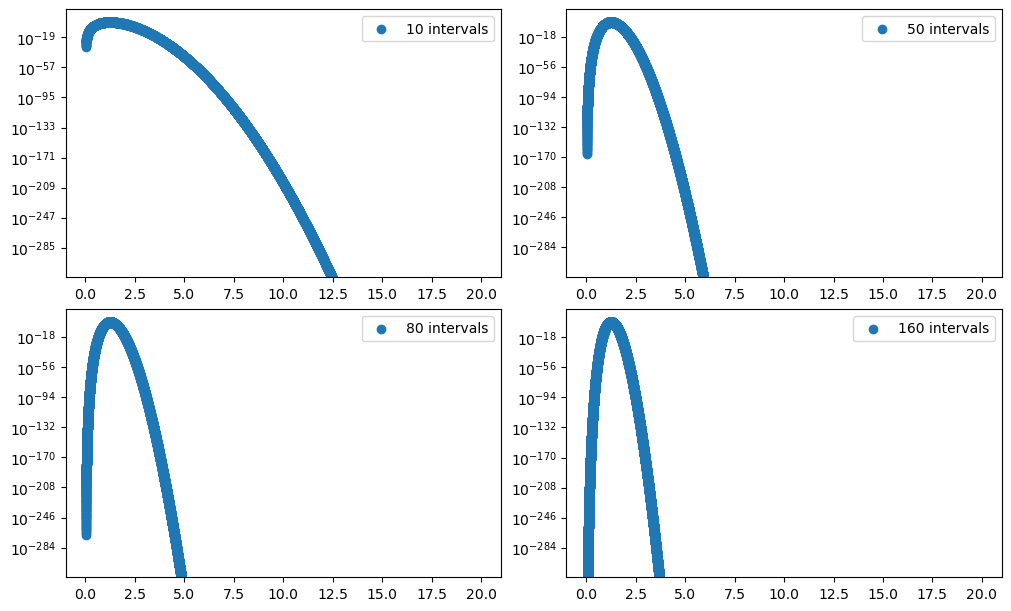

In [11]:
fig, axes = plt.subplot_mosaic(
    '''
    AB
    CD
    ''',
    figsize=(10, 6),
    constrained_layout = True
)

axes['A'].set_yscale('log')
axes['B'].set_yscale('log')
axes['C'].set_yscale('log')
axes['D'].set_yscale('log')

prob = np.convolve(ray_pdf,ray_pdf) * dx
num_days = 10
array = np.arange(0,num_days-2)
for day in array:
    prob = np.convolve(prob, ray_pdf) * dx
   
x_sum = num_days*x[0] + np.arange(len(prob)) * dx

x_ave = x_sum/num_days
prob_ave = prob*num_days
axes['A'].scatter(x_ave,
                   prob_ave,
            label = "10 intervals",)
axes['A'].legend()

prob = np.convolve(ray_pdf,ray_pdf) * dx
num_days = 50
array = np.arange(0,num_days-2)
for day in array:
    prob = np.convolve(prob, ray_pdf) * dx
   
x_sum = num_days*x[0] + np.arange(len(prob)) * dx
x_ave = x_sum/num_days
prob_ave = prob*num_days
axes['B'].scatter(x_ave,
          prob_ave,
            label = "50 intervals",)
axes['B'].legend()

prob = np.convolve(ray_pdf,ray_pdf) * dx
num_days = 80
array = np.arange(0,num_days-2)
for day in array:
    prob = np.convolve(prob, ray_pdf) * dx
   
x_sum = num_days*x[0] + np.arange(len(prob)) * dx

x_ave = x_sum/num_days
prob_ave = prob*num_days
axes['C'].scatter(x_ave,
          prob_ave,
            label = "80 intervals")
axes['C'].legend()

prob = np.convolve(ray_pdf,ray_pdf) * dx
num_days = 160
array = np.arange(0,num_days-2)
for day in array:
    prob = np.convolve(prob, ray_pdf) * dx
   
x_sum = num_days*x[0] + np.arange(len(prob)) * dx

x_ave = x_sum/num_days
prob_ave = prob*num_days
axes['D'].scatter(x_ave,
          prob_ave,
            label = "160 intervals",)
axes['D'].legend()



plt.show()

**B) Discuss how the shape changes. Does it approuach a Gaussian distribultion? If yes, after how many intervals?**

    The shape slower starts skewing more and more right until it approaches a Gaussian distribution.
    It looks more Gaussian that Rayleigh aroung 80 intervals
    It looks pretty Gaussian around 160 intervals

## **Problem 3**

**The discovery of optical/infra-red counterparts of Neutron star mergers initually detechted with gravity-waves is one of the great discoverys in the last few years, and has ushered in the age of "multi-messenger astrophysics." The science that can be done by matchhing a gravity-wave signal (directly measures the mass of the neutron stars and their distacne) with the optical emisson (reshift, nuclear astrophysics of the resulting explosion) is staggering. Lots of science from how the heaviest elements are formed to constraints on Dark Energy.**

**We're going to explore one of the analysis questions that comes up when looking for the optical counterparts (a new optical source) of a gravity wave signal. For this problem let's assume that we are using an optical telescope with a thermal noise background from the CCD (dark current, particularly an issue with older CCDs and/or infra-red CCDs). After flat-fielding, the background appears as a zero-mean Gaussian with constant width over the image.**

### **Version 1**

**You have an alert from LIGO that is also seen in with the X-ray/ultra-violet satellite SWIFT. SWIFT gives you a very precise location, so you take an image of that part of the sky. But because of SWIFT's accuracy, you know which pixel in your image to look for a counterpart in.**

**A) From looking at all the other pixels in your image, you can measure the width of the background Gaussian distribution X (pick something). Assuming you see a signal of strength Y (pick a floating-point number; typical optical CCDs are not sensitive enough to count photons so the readings are floating point brightnesses, not integer photons). Calculate the significance of your detection. Can you claim a discovery (traditionally 5-sigma or more)?**

In [100]:
X = 1.5 #distribution
Y = 8.72 #strength of the signal 

#Probability of finding that event at that pixel
dist_sf = stats.norm.sf(Y, loc=0, scale=X)
#sigma associated with that probability
dist_ppf = stats.norm.isf(dist_sf)

print(dist_ppf)

5.813333333333334


    Sigma is measured to be 5.81, so I could claim I made a discovery.

### **Verstion 2**

**You have an alert from LIGO, but no associated detection from SWIFT. This could be because it is a black hole-black hole merger, a black hole-neutron star merger (neither seem to emit X-rays or UV light), or it could because SWIFT was indisposed at the time (wrong side of the earth in its orbit). Whatever the cause, you know what region of the sky to look in, but not which pixel.**

**B) If you have to look for a signal in 10k pixels, what is the probability distribution of your background? (Clearly state the statistical question, then turn that into math using your background distribution from part 1 of this problem.)**

    Question: 
        If each of my pixel's background has a Gaussian distribution of 1.5 sigma, what what be the probability of finding a signal strength of 8.72 or above in 10k pixels?

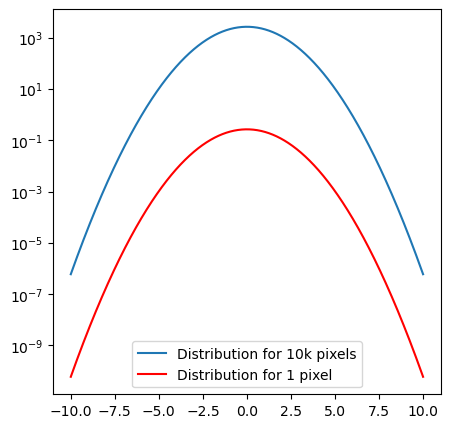

In [101]:
#Create evenly spaces x-values for my distribution pdf
x_values = np.linspace(-10,10,1000)
#my pdf for 10k pixels would be 10k times my pdf for one pixel
dist_pdf = stats.norm.pdf(x_values, loc=0, scale=X)

fig, ax = plt.subplots(
    figsize=(5,5)
)
ax.plot(x_values, 
         dist_pdf * 10000,
       label = 'Distribution for 10k pixels')
ax.plot(x_values, 
        dist_pdf,
       color = 'red',
       label = 'Distribution for 1 pixel')
ax.set_yscale('log')
ax.legend()

**C) Taking your brightest candidate signal from the region (assume it has the same signal as in part 1), calculate the significance of your detection.**

In [102]:
pixel = 10000
#sigma would be the isf of 10k time the original sf
dist_ppf = stats.norm.isf(dist_sf*pixel)

print(dist_ppf)

4.007977540394731


    The signal is no longer a significant

## **Probelm 4**

**The statistical issue we were exploring in the previous problem is called a trials factor (sometimes known as a look-elsewhere effect). This is an important effect, as if you search through a million locations, you would expect to see approximately 1 one-in-a-million event. However, it is also often over estimated how big an impact this makes on the sensitivity of a search. So in this part of the lab we are going to invert the problem.**

**Let us again assume we have a Gaussian background (same parameters as Problem 3).**

**A) Calculate the signal required for a 5-sigma detection in Version 1**

In [112]:
#Probability of finding ta 5-sigma event
dist_sf = stats.norm.sf(5)
#value associated with a 5-sigma probability on my Gaussian distribution
dist_isf_1 = stats.norm.isf(dist_sf, loc=0, scale=X)

print(dist_isf_1)

7.500000000000002


    For Version 1, I would only need to find a 7.5 strength signal

**B) Calculate the signal required for a 5-sigma detection in Version 2**

In [113]:
#value associated with a 5-sigma probability on my Gaussian distribution
dist_isf_2 = stats.norm.isf(dist_sf/pixel, loc=0, scale=X)

print(dist_isf_2)

9.825806419058


    For Version 2, I would need to find a 9.8 strength signal for my disvovery to be significant

**C) Discuss how much brighter the signal must be for discoverey if you have a trials factor of 10k. Looking at your probability distributions, explain why the sensitivity penalty due to a trials factor is so low.**

In [111]:
bright_ratio = dist_isf_2 / dist_isf_1
print(bright_ratio)

1.1329032239461714


    We are in the tails of the probability, so a change in x does not cause that much of a change in probability. 

**D) If you changed the trials factor significantly (orders of magnitude), how large is the effect on your 5-sigma sensitivity threshold?**

In [106]:
pixel_2 = 10000000

#value associated with a 5-sigma probability on my Gaussian distribution
dist_isf_3 = stats.norm.isf(dist_sf/pixel_2, loc=0, scale=X)
bright_ratio = dist_isf_3 / dist_isf_1
print(f'You will have a sensitivity threshold of {bright_ratio:.2f} for a trials factor of {pixel_2}')

You will have a sensitivity threshold of 1.50 for a trials factor of 10000000


    Increasing the trials factor three times in magnitude only caused the sensitivity to increase by 1.1 

**Extra credit: If you had a different distribution shape (non-Gaussian), how would that affect the sensitivity penalty of many trials? Clearly explain.**

In [118]:
#Expon

#Probability of finding ta 5-sigma event
dist_sf = stats.norm.sf(5)
#value associated with a 5-sigma probability on my Rayleigh distribution
dist_isf_1 = stats.expon.isf(dist_sf)
dist_isf_2 = stats.expon.isf(dist_sf/pixel)

sensitivity = dist_isf_2 / dist_isf_1
print(sensitivity)

1.6113734718784514


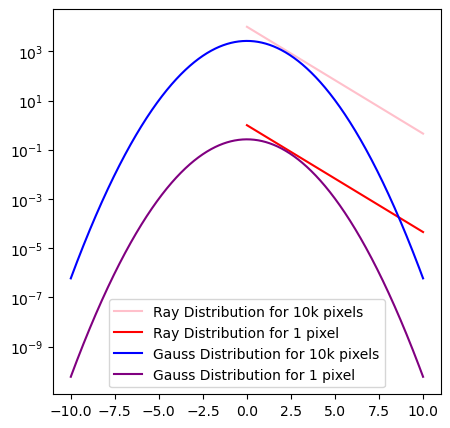

In [117]:
#Create evenly spaces x-values for my distribution pdf
x_values = np.linspace(0,10,1000)
#my pdf for 10k pixels would be 10k times my pdf for one pixel
dist_pdf = stats.expon.pdf(x_values)

fig, ax = plt.subplots(
    figsize=(5,5)
)
ax.plot(x_values, 
         dist_pdf * 10000,
       label = 'Ray Distribution for 10k pixels',
       color='pink')
ax.plot(x_values, 
        dist_pdf,
       color = 'red',
       label = 'Ray Distribution for 1 pixel')

#Create evenly spaces x-values for my distribution pdf
x_values = np.linspace(-10,10,1000)
#my pdf for 10k pixels would be 10k times my pdf for one pixel
dist_pdf = stats.norm.pdf(x_values, loc=0, scale=X)
ax.plot(x_values, 
         dist_pdf * 10000,
       label = 'Gauss Distribution for 10k pixels',
       color = 'blue')
ax.plot(x_values, 
        dist_pdf,
       color = 'purple',
       label = 'Gauss Distribution for 1 pixel')
ax.set_yscale('log')
ax.legend()



    The sensivity for an exponential distribution is higher than a Gaussian because the exponential function change much more in the right end of its tails. A small change in probability means a larger change in the x-value for an exponential.

In [120]:
#Rayleigh

#Probability of finding ta 5-sigma event
dist_sf = stats.norm.sf(5)
#value associated with a 5-sigma probability on my Rayleigh distribution
dist_isf_1 = stats.rayleigh.isf(dist_sf)
dist_isf_2 = stats.rayleigh.isf(dist_sf/pixel)

sensitivity = dist_isf_2 / dist_isf_1
print(sensitivity)

1.2693988624063168


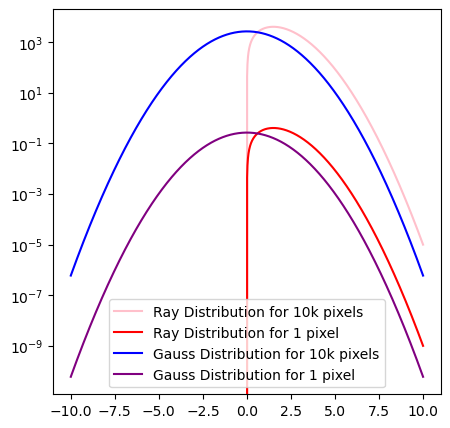

In [108]:
#Create evenly spaces x-values for my distribution pdf
x_values = np.linspace(0,10,1000)
#my pdf for 10k pixels would be 10k times my pdf for one pixel
dist_pdf = stats.rayleigh.pdf(x_values, loc=0, scale=X)

fig, ax = plt.subplots(
    figsize=(5,5)
)
ax.plot(x_values, 
         dist_pdf * 10000,
       label = 'Ray Distribution for 10k pixels',
       color='pink')
ax.plot(x_values, 
        dist_pdf,
       color = 'red',
       label = 'Ray Distribution for 1 pixel')

#Create evenly spaces x-values for my distribution pdf
x_values = np.linspace(-10,10,1000)
#my pdf for 10k pixels would be 10k times my pdf for one pixel
dist_pdf = stats.norm.pdf(x_values, loc=0, scale=X)
ax.plot(x_values, 
         dist_pdf * 10000,
       label = 'Gauss Distribution for 10k pixels',
       color = 'blue')
ax.plot(x_values, 
        dist_pdf,
       color = 'purple',
       label = 'Gauss Distribution for 1 pixel')
ax.set_yscale('log')
ax.legend()



    The sensitivity penalty is less for a Rayleigh distribution than for a Gaussian distribution for the same trials factor, but they are still very close. This is because the Rayleigh and Gaussian distribution act very similary at their right tails. 